In [1]:
!pip install -q segmentation-models-pytorch rasterio

from google.colab import drive
drive.mount('/content/drive')

import os, sys
REPO = '/content/sar-flood-unet'
if os.path.exists(REPO):
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/Ronnelpabalan/sar-flood-unet.git {REPO}
sys.path.insert(0, REPO)

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from src.dataset import Sen1Floods11, CLIP_DB
from src.metrics import MetricAccumulator

DATA_DIR = '/content/drive/MyDrive/sen1floods11'
print('CUDA:', torch.cuda.is_available(), '| clip ranges:', CLIP_DB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA: True | clip ranges: {'VV': (-25.7, -0.8), 'VH': (-38.1, -8.4)}


In [2]:
train_ds = Sen1Floods11(DATA_DIR, 'train', augment=True)
valid_ds = Sen1Floods11(DATA_DIR, 'valid', augment=False)
print('train chips:', len(train_ds), '| valid chips:', len(valid_ds))

img, lab = train_ds[0]
print('image:', tuple(img.shape), img.dtype, '| min', img.min().item(), 'max', img.max().item())
print('label:', tuple(lab.shape), lab.dtype, '| values', torch.unique(lab).tolist())

train chips: 252 | valid chips: 89
image: (2, 512, 512) torch.float32 | min 0.0 max 1.0000001192092896
label: (512, 512) torch.int64 | values [-1, 0, 1]


In [3]:
n_valid = sum(int((l != -1).sum()) for l in train_ds.labels)
n_water = sum(int((l == 1).sum()) for l in train_ds.labels)
print(f'valid train pixels: {n_valid:,}  (expected 57,279,257)')
print(f'water share: {100 * n_water / n_valid:.2f} %')

valid train pixels: 57,279,257  (expected 57,279,257)
water share: 9.51 %


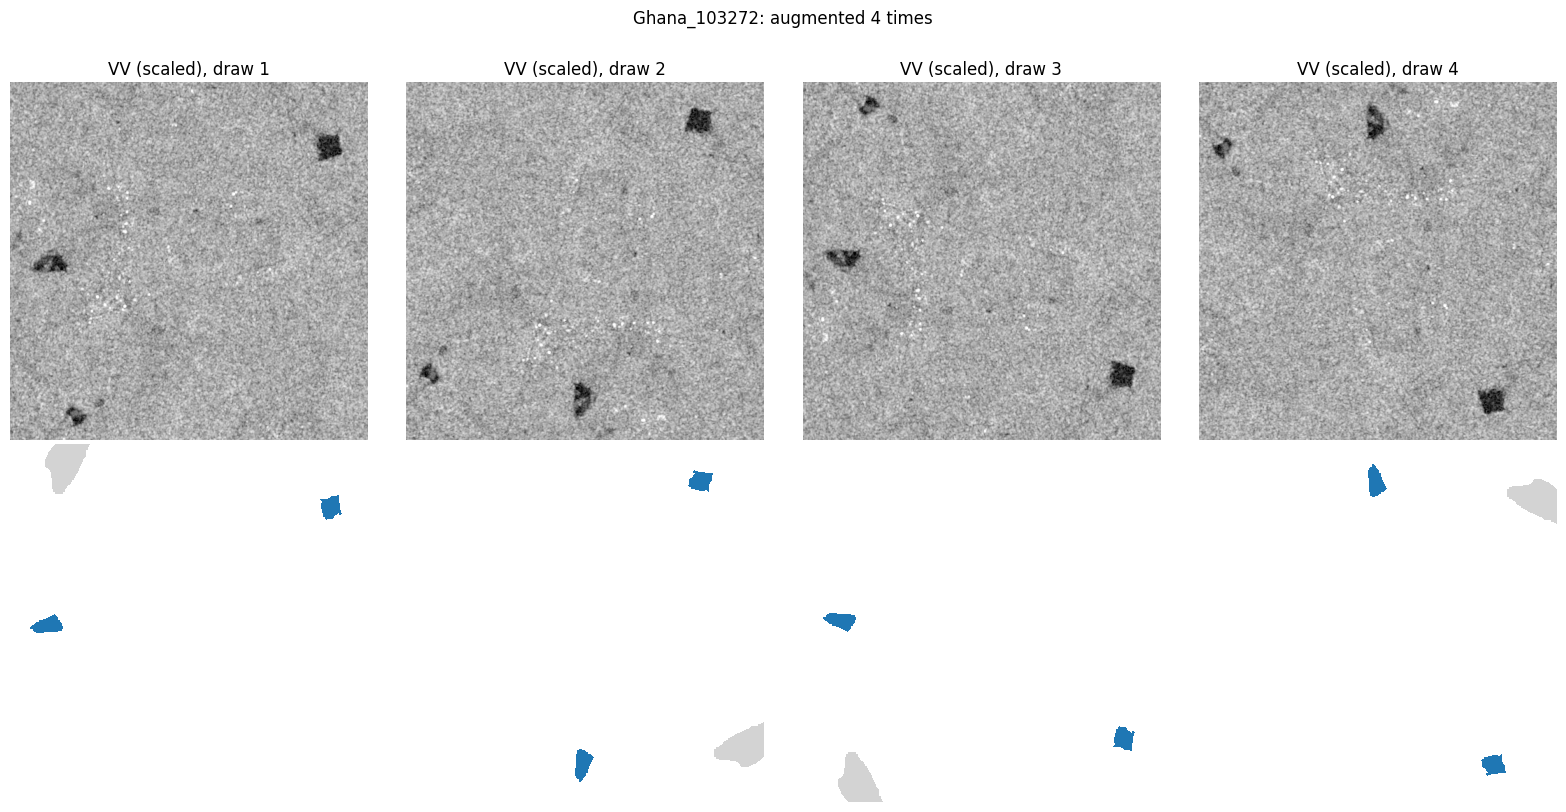

In [4]:
label_cmap = ListedColormap(['lightgrey', 'white', 'tab:blue'])   # -1, 0, 1
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j in range(4):
    img, lab = train_ds[0]                 # same chip, a new random flip/rotation each time
    ax[0, j].imshow(img[0], cmap='gray', vmin=0, vmax=1)
    ax[1, j].imshow(lab, cmap=label_cmap, vmin=-1, vmax=1, interpolation='nearest')
    ax[0, j].set_title(f'VV (scaled), draw {j + 1}')
    for a in ax[:, j]:
        a.axis('off')
plt.suptitle(f'{train_ds.chip_ids[0]}: augmented 4 times', y=1.01)
plt.tight_layout(); plt.show()

In [6]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
images, labels = next(iter(train_loader))
print('batch images:', tuple(images.shape), '| batch labels:', tuple(labels.shape))
print('batches per epoch:', len(train_loader))

batch images: (8, 2, 512, 512) | batch labels: (8, 512, 512)
batches per epoch: 32


In [3]:
from src.losses import bce_dice_loss

# Test 1: logits 0 (p = 0.5) on one water and one land pixel; two pixels ignored
logits = torch.zeros(1, 1, 2, 2)
target = torch.tensor([[[1, 0], [-1, -1]]])
expected = np.log(2) + 1/3        # BCE = ln 2; Dice = 1 - (2*0.5 + 1) / (1 + 1 + 1) = 1/3
print(f'Test 1: {bce_dice_loss(logits, target).item():.4f}  (expected {expected:.4f})')

# Test 2: ignored pixels must not change the loss, whatever the model predicts there
logits2 = torch.tensor([[[[0., 0.], [50., -50.]]]])
print(f'Test 2: {bce_dice_loss(logits2, target).item():.4f}  (expected {expected:.4f})')

# Test 3: perfect, confident prediction -> loss close to 0
logits3 = torch.tensor([[[[20., -20.], [0., 0.]]]])
print(f'Test 3: {bce_dice_loss(logits3, target).item():.6f}  (expected ~0)')

# Test 4: a batch with no labelled pixels -> loss 0, and backpropagation still works
logits4 = torch.zeros(1, 1, 2, 2, requires_grad=True)
loss4 = bce_dice_loss(logits4, torch.full((1, 2, 2), -1))
loss4.backward()
print(f'Test 4: {loss4.item():.4f}  (expected 0.0000), gradient OK: {logits4.grad is not None}')

Test 1: 1.0265  (expected 1.0265)
Test 2: 1.0265  (expected 1.0265)
Test 3: 0.000000  (expected ~0)
Test 4: 0.0000  (expected 0.0000), gradient OK: True


In [4]:
import segmentation_models_pytorch as smp

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)

model = smp.Unet(
    encoder_name='resnet34',        # the "left side" of the U: a ResNet34
    encoder_weights='imagenet',     # start from weights pretrained on ImageNet photos
    in_channels=2,                  # VV and VH instead of RGB
    classes=1,                      # one output channel: water logit
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f'Parameters: {n_params / 1e6:.1f} million | device: {device}')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 24.4 million | device: cuda


In [7]:
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():                       # no training here, just look at the output
    logits = model(images)
print('input :', tuple(images.shape))
print('output:', tuple(logits.shape))
print(f'loss before any training: {bce_dice_loss(logits, labels).item():.3f}')

input : (8, 2, 512, 512)
output: (8, 1, 512, 512)
loss before any training: 1.710


In [8]:
xb = torch.from_numpy(np.stack(train_ds.images[:4])).to(device)    # 4 fixed chips, no augmentation
yb = torch.from_numpy(np.stack(train_ds.labels[:4])).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
model.train()
for step in range(1, 101):
    optimizer.zero_grad()                   # clear gradients from the previous step
    loss = bce_dice_loss(model(xb), yb)     # forward pass + loss
    loss.backward()                         # work out how each weight should change
    optimizer.step()                        # change the weights a little
    if step in (1, 10, 25, 50, 100):
        print(f'step {step:3d}  loss {loss.item():.3f}')

model.eval()
with torch.no_grad():
    pred = (torch.sigmoid(model(xb)) > 0.5).cpu().numpy()
acc = MetricAccumulator()
for p, l in zip(pred[:, 0], yb.cpu().numpy()):
    acc.add(p, l)
print(f"IoU on these same 4 chips: {acc.compute()['iou']:.3f}")

step   1  loss 2.257
step  10  loss 1.702
step  25  loss 1.562
step  50  loss 1.349
step 100  loss 1.153
IoU on these same 4 chips: 0.594


In [9]:
import time
import pandas as pd
from torch.utils.data import DataLoader

del model, optimizer                        # discard the 4-chip test model
torch.cuda.empty_cache()

torch.manual_seed(0)
model = smp.Unet(encoder_name='resnet34', encoder_weights='imagenet',
                 in_channels=2, classes=1).to(device)

EPOCHS = 40
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_ds, batch_size=8, shuffle=False, num_workers=0)
print('train batches:', len(train_loader), '| valid batches:', len(valid_loader))

train batches: 32 | valid batches: 12


In [10]:
def run_epoch(model, loader, optimizer=None):
    """Train for one epoch if an optimizer is given, otherwise just evaluate.
    Returns (mean loss, pooled metrics dict)."""
    training = optimizer is not None
    model.train(training)
    acc = MetricAccumulator()
    total_loss, n_chips = 0.0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = bce_dice_loss(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(images)
            n_chips += len(images)
            pred = (logits.detach() > 0).squeeze(1).cpu().numpy()   # logit > 0 means probability > 0.5
            for p, l in zip(pred, labels.cpu().numpy()):
                acc.add(p, l)
    return total_loss / n_chips, acc.compute()

In [11]:
CKPT_DIR = '/content/drive/MyDrive/sen1floods11/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)
CKPT = f'{CKPT_DIR}/unet_resnet34_best.pth'
LOG = f'{CKPT_DIR}/unet_training_log.csv'

history, best_iou = [], -1.0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_m = run_epoch(model, train_loader, optimizer)
    va_loss, va_m = run_epoch(model, valid_loader)
    scheduler.step()

    history.append({'epoch': epoch, 'lr': optimizer.param_groups[0]['lr'],
                    'train_loss': tr_loss, 'train_iou': tr_m['iou'],
                    'val_loss': va_loss, 'val_iou': va_m['iou'], 'val_f1': va_m['f1'],
                    'val_precision': va_m['precision'], 'val_recall': va_m['recall']})
    pd.DataFrame(history).to_csv(LOG, index=False)        # saved every epoch, survives a disconnect

    is_best = va_m['iou'] > best_iou
    if is_best:
        best_iou = va_m['iou']
        torch.save({'model_state': model.state_dict(), 'epoch': epoch, 'val_iou': best_iou}, CKPT)

    print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} IoU {tr_m['iou']:.3f} | "
          f"val loss {va_loss:.3f} IoU {va_m['iou']:.3f} | {time.time() - t0:.0f}s"
          + ('  * best, saved' if is_best else ''))

print(f'\nBest validation IoU: {best_iou:.3f}')

epoch  1 | train loss 1.480 IoU 0.173 | val loss 1.213 IoU 0.463 | 23s  * best, saved
epoch  2 | train loss 1.193 IoU 0.362 | val loss 0.926 IoU 0.560 | 23s  * best, saved
epoch  3 | train loss 1.023 IoU 0.454 | val loss 0.883 IoU 0.587 | 23s  * best, saved
epoch  4 | train loss 0.916 IoU 0.485 | val loss 0.752 IoU 0.589 | 23s  * best, saved
epoch  5 | train loss 0.860 IoU 0.476 | val loss 0.666 IoU 0.610 | 23s  * best, saved
epoch  6 | train loss 0.818 IoU 0.467 | val loss 0.656 IoU 0.621 | 23s  * best, saved
epoch  7 | train loss 0.767 IoU 0.502 | val loss 0.584 IoU 0.637 | 23s  * best, saved
epoch  8 | train loss 0.695 IoU 0.532 | val loss 0.546 IoU 0.614 | 23s
epoch  9 | train loss 0.701 IoU 0.520 | val loss 0.549 IoU 0.612 | 22s
epoch 10 | train loss 0.631 IoU 0.565 | val loss 0.860 IoU 0.405 | 23s
epoch 11 | train loss 0.644 IoU 0.537 | val loss 0.501 IoU 0.600 | 22s
epoch 12 | train loss 0.648 IoU 0.528 | val loss 0.569 IoU 0.576 | 22s
epoch 13 | train loss 0.590 IoU 0.562 | val

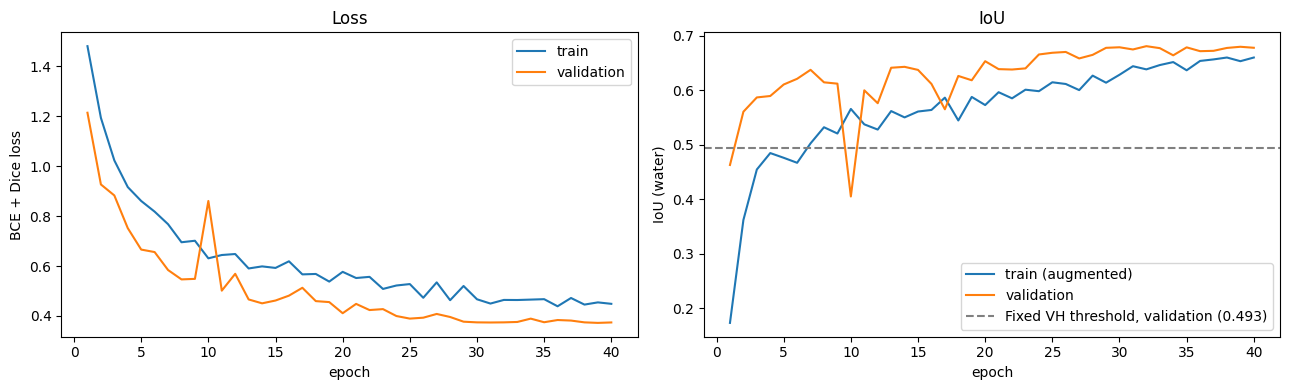

epoch            32.000
lr                0.000
train_loss        0.464
train_iou         0.638
val_loss          0.375
val_iou           0.681
val_f1            0.810
val_precision     0.832
val_recall        0.789


In [12]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h['epoch'], h['train_loss'], label='train')
ax[0].plot(h['epoch'], h['val_loss'], label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('BCE + Dice loss'); ax[0].set_title('Loss'); ax[0].legend()

ax[1].plot(h['epoch'], h['train_iou'], label='train (augmented)')
ax[1].plot(h['epoch'], h['val_iou'], label='validation')
ax[1].axhline(0.493, color='grey', ls='--', label='Fixed VH threshold, validation (0.493)')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('IoU (water)'); ax[1].set_title('IoU'); ax[1].legend()
plt.tight_layout(); plt.show()

best = h.loc[h['val_iou'].idxmax()]
print(best.round(3).to_string())

In [13]:
from google.colab import files
files.download(LOG)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>